# PS7: YOLO on the Flowers dataset
Dataset: https://www.kaggle.com/datasets/imsparsh/flowers-dataset (train/<daisy, dandelion, rose, sunflower, tulip>).
The dataset has class folders but no bounding boxes, so YOLOv8 is used in classification mode (yolov8n-cls).

Install once: `pip install ultralytics`

In [1]:
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
from ultralytics import YOLO

SRC = Path("../datasets/flowers-dataset/train")
OUT = Path("flowers_yolo")
EPOCHS = 10

In [2]:
# YOLO classification needs train/<class> and val/<class>, so 20% of each class becomes validation.
random.seed(42)
for cls_dir in sorted(p for p in SRC.iterdir() if p.is_dir()):
    files = sorted(cls_dir.glob("*"))
    random.shuffle(files)
    n_val = int(0.2 * len(files))
    for split, part in [("val", files[:n_val]), ("train", files[n_val:])]:
        dst = OUT / split / cls_dir.name
        dst.mkdir(parents=True, exist_ok=True)
        for f in part:
            shutil.copy(f, dst / f.name)
    print(f"{cls_dir.name:12s} train={len(files) - n_val}  val={n_val}")

daisy        train=401  val=100


dandelion    train=517  val=129


rose         train=398  val=99


sunflower    train=396  val=99


tulip        train=486  val=121


In [3]:
model = YOLO("yolov8n-cls.pt")
model.train(data=str(OUT.resolve()), epochs=EPOCHS, imgsz=224, seed=42)
save_dir = Path(model.trainer.save_dir)

Ultralytics 8.4.212  Python-3.10.11 torch-2.10.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS07_YOLO_Flowers\flowers_yolo, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=Tru

train: C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS07_YOLO_Flowers\flowers_yolo\train... found 2198 images in 5/5 classes  


val: C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS07_YOLO_Flowers\flowers_yolo\val... found 548 images in 5/5 classes  


test: None...


Overriding model.yaml nc=1000 with nc=5


... (1,642 outputs left out)

               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 18/18 5.1it/s 3.5s

                   all      0.953          1


Speed: 0.0ms preprocess, 2.1ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS07_YOLO_Flowers\runs\classify\train


Ultralytics 8.4.212  Python-3.10.11 torch-2.10.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)


YOLOv8n-cls summary (fused): 30 layers, 1,441,285 parameters, 0 gradients, 3.3 GFLOPs


train: C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS07_YOLO_Flowers\flowers_yolo\train... found 2198 images in 5/5 classes  


val: C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS07_YOLO_Flowers\flowers_yolo\val... found 548 images in 5/5 classes  


test: None...


val: Fast image access  (ping: 0.1±0.0 ms, read: 347.1±241.2 MB/s, size: 50.8 KB)


... (22 outputs left out)

                   all      0.953          1


Speed: 0.0ms preprocess, 1.9ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS07_YOLO_Flowers\runs\classify\val


Top-1 accuracy: 0.9526   Top-5 accuracy: 1.0000


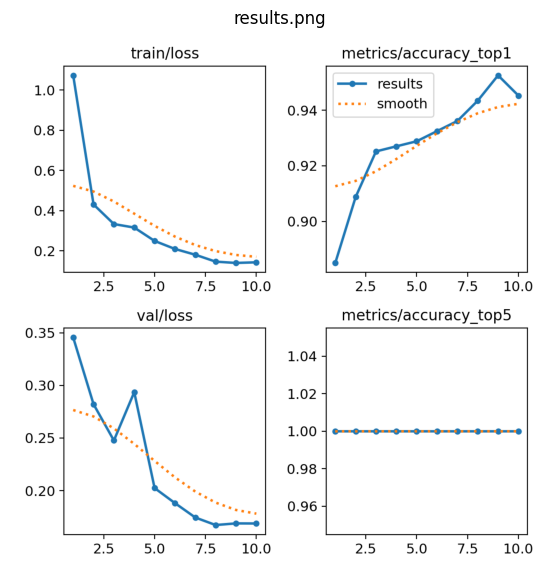

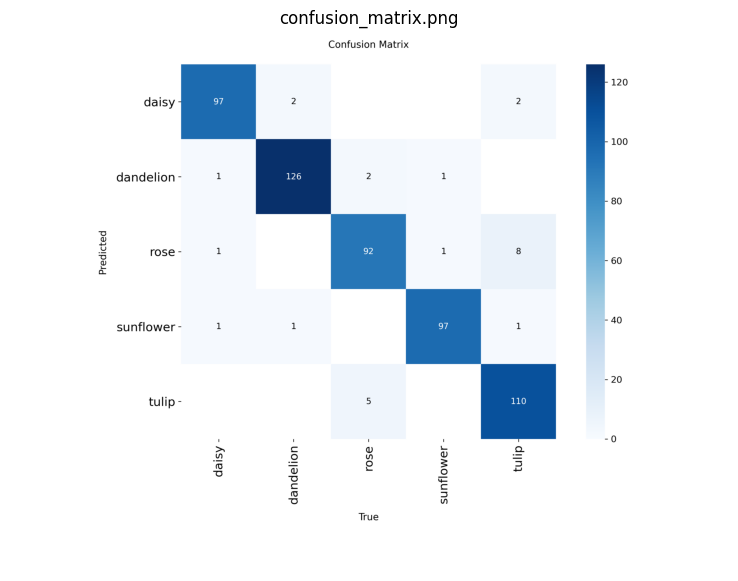

In [4]:
metrics = model.val(data=str(OUT.resolve()))
print(f"Top-1 accuracy: {metrics.top1:.4f}   Top-5 accuracy: {metrics.top5:.4f}")

for name in ["results.png", "confusion_matrix.png"]:
    plt.figure(figsize=(12, 7))
    plt.imshow(plt.imread(save_dir / name))
    plt.title(name)
    plt.axis("off")
    plt.show()

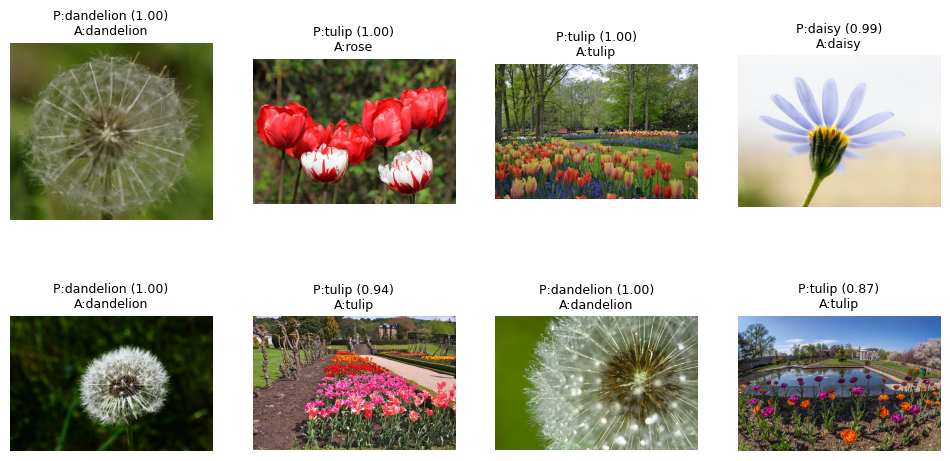

In [5]:
val_images = sorted((OUT / "val").rglob("*.*"))
samples = random.sample(val_images, 8)
plt.figure(figsize=(12, 6))
for i, img in enumerate(samples):
    r = model.predict(str(img), verbose=False)[0]
    plt.subplot(2, 4, i + 1)
    plt.imshow(r.orig_img[..., ::-1])
    plt.title(f"P:{r.names[r.probs.top1]} ({r.probs.top1conf:.2f})\nA:{img.parent.name}", fontsize=9)
    plt.axis("off")
plt.show()